# Neural Network from Scratch: explained step by step
Run the cells **top to bottom** (Shift+Enter). Every cell does one job. No shortcuts: only `for` loops and plain functions, so you can follow every number.

**Problem (XOR):** output 1 when the two inputs are different, 0 when they are the same.

| input 1 | input 2 | expected output |
|---|---|---|
| 0 | 0 | 0 |
| 0 | 1 | 1 |
| 1 | 0 | 1 |
| 1 | 1 | 0 |

**Network shape:** 2 inputs -> 4 hidden neurons -> 1 output neuron.

**Training = repeat this 5000 times:**
1. **Forward pass:** push inputs through the network to get a prediction.
2. **Loss:** measure how wrong the prediction is: `(prediction - expected)^2`.
3. **Backward pass (backpropagation):** find how much each weight contributed to the error.
4. **Update:** nudge every weight a small step in the direction that reduces the error.

## Step 1: Imports and data

In [9]:
import math                       # for exp(), used in the sigmoid function
import random                      # for random starting weights
import matplotlib.pyplot as plt    # ONLY used to draw graphs, not for the network

random.seed(1)                     # same random numbers every run, so results are repeatable

# The 4 training examples. Each row of X is one example: [input1, input2]
X = [[0, 0],
     [0, 1],
     [1, 0],
     [1, 1]]

# The correct answer for each row of X, in the same order
Y = [0, 1, 1, 0]

n_inputs = 2          # number of inputs
n_hidden = 4          # number of neurons in the hidden layer
learning_rate = 0.5   # size of each weight nudge (too big = unstable, too small = slow)
epochs = 5000         # how many times we loop over all 4 examples

## Step 2: Create the weights
A weight is a number that says how strongly one neuron listens to another. We start with **random** values. They cannot all be zero, otherwise every hidden neuron would compute the same thing and learn the same thing forever.

- `W1[i][j]` = weight from **input i** to **hidden neuron j**
- `b1[j]` = bias of hidden neuron j (a constant added before the activation)
- `W2[j]` = weight from **hidden neuron j** to the output neuron
- `b2` = bias of the output neuron

In [2]:
# Weights from inputs to hidden layer: a table with 2 rows (inputs) and 4 columns (hidden neurons)
W1 = []
for i in range(n_inputs):
    row = []
    for j in range(n_hidden):
        row.append(random.uniform(-1, 1))   # random number between -1 and 1
    W1.append(row)

# One bias per hidden neuron, starting at 0
b1 = []
for j in range(n_hidden):
    b1.append(0.0)

# Weights from hidden layer to the single output neuron: one per hidden neuron
W2 = []
for j in range(n_hidden):
    W2.append(random.uniform(-1, 1))

# Bias of the output neuron
b2 = 0.0

print("W1 (input -> hidden):")
for row in W1:
    print("  ", [round(w, 3) for w in row])
print("W2 (hidden -> output):", [round(w, 3) for w in W2])

W1 (input -> hidden):
   [-0.731, 0.695, 0.528, -0.49]
   [-0.009, -0.101, 0.303, 0.577]
W2 (hidden -> output): [-0.812, -0.943, 0.672, -0.134]


## Step 3: Sigmoid activation function
Each neuron computes a weighted sum `z`, then squashes it with sigmoid into a value between 0 and 1:

`sigmoid(z) = 1 / (1 + e^(-z))`

**Why we need it:** without a non-linear function like this, stacking layers is mathematically the same as one layer, and a single layer cannot solve XOR. The squashing is what lets hidden neurons build a curved decision boundary.

In [3]:
def sigmoid(z):
    return 1 / (1 + math.exp(-z))

# Quick feel for it: big negative -> near 0, zero -> 0.5, big positive -> near 1
print("sigmoid(-5) =", round(sigmoid(-5), 4))
print("sigmoid(0)  =", sigmoid(0))
print("sigmoid(5)  =", round(sigmoid(5), 4))

sigmoid(-5) = 0.0067
sigmoid(0)  = 0.5
sigmoid(5)  = 0.9933


## Step 4: Forward pass
For one example `x` we compute:
1. Each hidden neuron: `z = b1[j] + x[0]*W1[0][j] + x[1]*W1[1][j]`, then `sigmoid(z)`
2. The output neuron: `z = b2 + sum(hidden[j] * W2[j])`, then `sigmoid(z)`

The function returns both the hidden outputs (needed later for backprop) and the final output.

In [4]:
def forward(x):
    # ---- hidden layer ----
    hidden = []                          # will hold the 4 hidden neuron outputs
    for j in range(n_hidden):
        total = b1[j]                    # start with the bias
        for i in range(n_inputs):
            total = total + x[i] * W1[i][j]   # add input * weight
        hidden.append(sigmoid(total))    # squash and store

    # ---- output layer ----
    total = b2                           # start with the output bias
    for j in range(n_hidden):
        total = total + hidden[j] * W2[j]     # add hidden output * weight
    output = sigmoid(total)

    return hidden, output

## Step 5: Trace one forward pass with real numbers
Before training, the network is random, so its answer is wrong. Look at every number it computes for the input `[1, 0]` (expected output: 1).

In [5]:
x = [1, 0]
print("Input:", x)
print()

hidden_outputs = []
for j in range(n_hidden):
    total = b1[j]
    for i in range(n_inputs):
        total = total + x[i] * W1[i][j]
    h = sigmoid(total)
    hidden_outputs.append(h)
    print("hidden neuron", j, ": weighted sum =", round(total, 3), "-> after sigmoid =", round(h, 3))

total = b2
for j in range(n_hidden):
    total = total + hidden_outputs[j] * W2[j]
output = sigmoid(total)
print()
print("output neuron: weighted sum =", round(total, 3), "-> after sigmoid =", round(output, 3))
print("expected = 1, error =", round(output - 1, 3), ", loss =", round((output - 1) ** 2, 3))

Input: [1, 0]

hidden neuron 0 : weighted sum = -0.731 -> after sigmoid = 0.325
hidden neuron 1 : weighted sum = 0.695 -> after sigmoid = 0.667
hidden neuron 2 : weighted sum = 0.528 -> after sigmoid = 0.629
hidden neuron 3 : weighted sum = -0.49 -> after sigmoid = 0.38

output neuron: weighted sum = -0.522 -> after sigmoid = 0.372
expected = 1, error = -0.628 , loss = 0.394


## Step 6: Training (forward + backpropagation + update)
For each example we do the 4 stages below.

**Loss for one example:** `loss = (output - y)^2`

**Backprop is the chain rule.** We want `d loss / d weight` for every weight, so we multiply derivatives along the path from the loss back to that weight.

- Derivative of the loss w.r.t. the output: `2 * (output - y)`
- Derivative of sigmoid: `output * (1 - output)`
- **output_delta** = `2 * (output - y) * output * (1 - output)`. This is how much the loss changes when the output neuron's weighted sum changes.
- Gradient of an output weight `W2[j]` = `output_delta * hidden[j]`
- **hidden_delta[j]** = `output_delta * W2[j] * hidden[j] * (1 - hidden[j])`. The error is sent back through `W2[j]`, then through hidden neuron j's sigmoid.
- Gradient of `W1[i][j]` = `hidden_delta[j] * x[i]`
- Gradient of a bias = its delta (a bias is a weight whose input is always 1)

**Update rule:** `weight = weight - learning_rate * gradient`. The minus sign moves the weight downhill on the loss.

In [6]:
loss_history = []                 # we store the loss every epoch to draw the graph later

for epoch in range(epochs):
    epoch_loss = 0.0

    for n in range(len(X)):       # go through the 4 examples one by one
        x = X[n]
        y = Y[n]

        # ---------- 1. FORWARD PASS ----------
        hidden, output = forward(x)

        # ---------- 2. LOSS ----------
        epoch_loss = epoch_loss + (output - y) ** 2

        # ---------- 3. BACKWARD PASS (compute deltas) ----------
        # delta for the output neuron
        output_delta = 2 * (output - y) * output * (1 - output)

        # delta for each hidden neuron (uses the OLD W2, so compute before updating W2)
        hidden_deltas = []
        for j in range(n_hidden):
            delta = output_delta * W2[j] * hidden[j] * (1 - hidden[j])
            hidden_deltas.append(delta)

        # ---------- 4. UPDATE WEIGHTS ----------
        # output layer
        for j in range(n_hidden):
            W2[j] = W2[j] - learning_rate * output_delta * hidden[j]
        b2 = b2 - learning_rate * output_delta

        # hidden layer
        for j in range(n_hidden):
            for i in range(n_inputs):
                W1[i][j] = W1[i][j] - learning_rate * hidden_deltas[j] * x[i]
            b1[j] = b1[j] - learning_rate * hidden_deltas[j]

    # average loss over the 4 examples for this epoch
    loss_history.append(epoch_loss / len(X))

    # print progress a few times so you can watch the loss fall
    if epoch % 1000 == 0 or epoch == epochs - 1:
        print("epoch", epoch, " loss =", round(loss_history[-1], 5))

epoch 0  loss = 0.29742
epoch 1000  loss = 0.00196
epoch 2000  loss = 0.00058
epoch 3000  loss = 0.00033
epoch 4000  loss = 0.00022
epoch 4999  loss = 0.00017


## Step 7: Check the predictions
An output close to 0 means "0", close to 1 means "1". We round to the nearest to get the final class.

In [7]:
print("input   predicted   rounded   expected")
correct = 0
for n in range(len(X)):
    hidden, output = forward(X[n])
    rounded = 1 if output >= 0.5 else 0
    if rounded == Y[n]:
        correct = correct + 1
    print(X[n], "  ", round(output, 3), "     ", rounded, "      ", Y[n])

print()
print("Accuracy:", correct, "/", len(X))

input   predicted   rounded   expected
[0, 0]    0.011       0        0
[0, 1]    0.986       1        1
[1, 0]    0.987       1        1
[1, 1]    0.015       0        0

Accuracy: 4 / 4


## Step 8: Graphs
- **Left, loss curve:** how wrong the network was at each epoch. It should fall and flatten near 0.
- **Right, decision map:** we feed many points between 0 and 1 into the trained network and colour each by its output (red near 1, blue near 0). The 4 dots are the training examples. A correct XOR network is red on one diagonal and blue on the other.

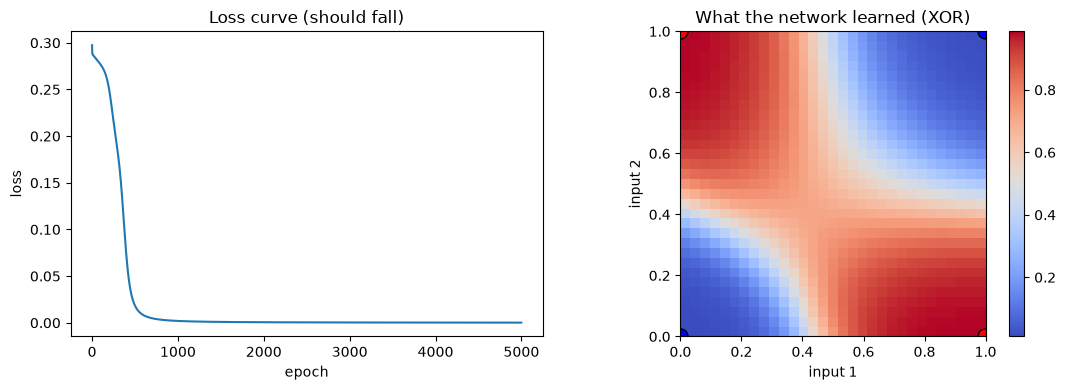

In [8]:
# Build the grid of outputs: 31 x 31 points covering inputs from 0 to 1
grid = []
for row in range(31):
    grid_row = []
    for col in range(31):
        input1 = col / 30             # goes 0.0, 0.033, ..., 1.0
        input2 = row / 30
        hidden, output = forward([input1, input2])
        grid_row.append(output)
    grid.append(grid_row)

# Colours of the 4 training dots: blue if expected 0, red if expected 1
dot_x = []
dot_y = []
dot_colors = []
for n in range(len(X)):
    dot_x.append(X[n][0])
    dot_y.append(X[n][1])
    if Y[n] == 1:
        dot_colors.append("red")
    else:
        dot_colors.append("blue")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# Left plot: loss curve
axes[0].plot(loss_history)
axes[0].set_title("Loss curve (should fall)")
axes[0].set_xlabel("epoch")
axes[0].set_ylabel("loss")

# Right plot: decision map
picture = axes[1].imshow(grid, origin="lower", extent=[0, 1, 0, 1], cmap="coolwarm")
plt.colorbar(picture, ax=axes[1])
axes[1].scatter(dot_x, dot_y, c=dot_colors, edgecolors="black", s=120)
axes[1].set_title("What the network learned (XOR)")
axes[1].set_xlabel("input 1")
axes[1].set_ylabel("input 2")

plt.tight_layout()
plt.show()

## Experiments to understand it deeper
Change one thing, re-run **all cells from the top**, and watch the graph.
- `learning_rate = 0.01` -> loss falls very slowly. `learning_rate = 5` -> may become unstable.
- `n_hidden = 1` -> XOR cannot be solved (accuracy stays below 4/4). This proves hidden neurons are needed.
- `epochs = 300` -> network stops before it has learned.
- Change `random.seed(1)` to another number -> different starting weights, usually the same final result.